# Лабораторна робота 1: Класифікація мережевого трафіку (NSL-KDD)

**Датасет:** [NSL-KDD](https://www.kaggle.com/datasets/hassan06/nslkdd) це покращена версія KDD Cup 1999 для задачі виявлення мережевих вторгнень (network intrusion detection). Кожен запис описує одне мережеве з'єднання; цільова змінна `class` приймає значення `normal` або `anomaly` (бінарна класифікація вже готова, без додаткового групування)

## 1. Завантаження та первинний аналіз даних

### 1.1. Завантаження датасету через `kagglehub`

In [92]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hassan06/nslkdd")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\FidJen\.cache\kagglehub\datasets\hassan06\nslkdd\versions\1


### 1.2. Виправлення формату `.arff`

Оригінальні `.arff`-файли NSL-KDD містять нестандартно оформлені списки значень номінальних атрибутів (без лапок навколо рядкових значень), через що стандартний `scipy.io.arff.loadarff` не може їх коректно розпарсити. Виправляю формат рядків `@attribute` (обгортаю кожне значення в лапки), зберігаючи виправлені копії файлів окремо

In [93]:
import re
import os
import pandas as pd

from scipy.io import arff


files_map = {
    'KDDTrain+.arff': 'KDDTrain_fixed.arff',
    'KDDTest+.arff': 'KDDTest_fixed.arff',
}


def fix_attribute_line(line):
    match = re.match(r"(@attribute\s+'[^']+'\s*)\{(.+)\}\s*$", line.strip(), re.IGNORECASE)
    if not match:
        return line
    head, values_str = match.groups()
    values = [v.strip().strip("'\"") for v in values_str.split(',')]
    return f"{head}{{{','.join(repr(v) for v in values)}}}\n".replace('"', "'")

for src_name, dst_name in files_map.items():
    src_path = os.path.join(path, src_name)
    dst_path = dst_name

    with open(src_path, 'r') as fin, open(dst_path, 'w') as fout:
        for line in fin:
            if line.strip().lower().startswith('@attribute') and '{' in line:
                line = fix_attribute_line(line)
            fout.write(line)

    print(f'Записано: {os.path.abspath(dst_path)}')

Записано: D:\Study\Semester_1\IAD\Lab1\KDDTrain_fixed.arff
Записано: D:\Study\Semester_1\IAD\Lab1\KDDTest_fixed.arff


### 1.3. Завантаження даних у DataFrame, назви колонок і розмір датасета

In [94]:
train_data, train_meta = arff.loadarff('KDDTrain_fixed.arff')
df_train = pd.DataFrame(train_data)

print(df_train.columns)
print(df_train.shape)

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'class'],
      dtype='str')
(125973, 42)


**Результат:** датасет містить **125973 рядки та 42 колонки** (41 ознака + 1 цільова змінна `class`)

### 1.4. Визначення ознак (features) та цільової змінної (target)

In [95]:
X = df_train.drop(columns=['class']).values
y = df_train['class'].values

print(f"Ознак (features): {X.shape[1]}")
print(f"Розмір X: {X.shape}")
print(f"Розмір y: {y.shape}")
print(f"\nЦільова змінна: 'class'")


Ознак (features): 41
Розмір X: (125973, 41)
Розмір y: (125973,)

Цільова змінна: 'class'


**Ознаки (features):** усі 41 колонка, окрім `class` це характеристики мережевого з'єднання (тривалість, протокол, обсяг переданих байтів, статистики трафіку тощо). **Цільова змінна (target):** `class` це бінарна мітка з'єднання: `normal` або `anomaly`

### 1.5. Типи даних та розподіл об'єктів за класами

In [96]:
print(df_train.dtypes.value_counts())
print(df_train['class'].value_counts())
print(df_train['class'].value_counts(normalize=True).round(3))

float64    34
object      8
Name: count, dtype: int64
class
b'normal'     67343
b'anomaly'    58630
Name: count, dtype: int64
class
b'normal'     0.535
b'anomaly'    0.465
Name: proportion, dtype: float64


- Типи даних: 34 числові колонки (`float64`) та 8 текстових/номінальних (`object`)
- Розподіл класів: `normal` - 67343 (53.5%), `anomaly` - 58630 (46.5%). Класи **відносно збалансовані** (без сильного перекосу), тому `accuracy` можна використовувати як одну з   адекватних метрик поряд з `classification_report`

## 2. Попередня обробка даних

Оскільки пропусків не виявлено цей крок зводиться до обробки категоріальних ознак

### 2.1. Перевірка пропущених значень

In [97]:
print(df_train.isnull().sum())

duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate                  0
srv_diff_h

### 2.2. Декодування та повний огляд нечислових ознак

У п. 1.5 виявлено **8** колонок типу `object`, хоча очікуваних категоріальних ознак лише 3 (`protocol_type`, `service`, `flag`) + `class`. Спершу декодую всі текстові колонки з byte-strings (`b'tcp'` → `'tcp'`) це прибире плутанину при подальшому кодуванні та порівнянні значень. Потім виведу всі object-колонки, щоб побачити, які саме 4 додаткові колонки там ховаються

In [98]:
object_cols = df_train.select_dtypes(include='object').columns.tolist()
print("Усі колонки типу object:", object_cols)

for col in object_cols:
    df_train[col] = df_train[col].str.decode('utf-8')

for col in object_cols:
    print(f"{col}: {sorted(df_train[col].unique())}")

Усі колонки типу object: ['protocol_type', 'service', 'flag', 'land', 'logged_in', 'is_host_login', 'is_guest_login', 'class']
protocol_type: ['icmp', 'tcp', 'udp']
service: ['IRC', 'X11', 'Z39_50', 'aol', 'auth', 'bgp', 'courier', 'csnet_ns', 'ctf', 'daytime', 'discard', 'domain', 'domain_u', 'echo', 'eco_i', 'ecr_i', 'efs', 'exec', 'finger', 'ftp', 'ftp_data', 'gopher', 'harvest', 'hostnames', 'http', 'http_2784', 'http_443', 'http_8001', 'imap4', 'iso_tsap', 'klogin', 'kshell', 'ldap', 'link', 'login', 'mtp', 'name', 'netbios_dgm', 'netbios_ns', 'netbios_ssn', 'netstat', 'nnsp', 'nntp', 'ntp_u', 'other', 'pm_dump', 'pop_2', 'pop_3', 'printer', 'private', 'red_i', 'remote_job', 'rje', 'shell', 'smtp', 'sql_net', 'ssh', 'sunrpc', 'supdup', 'systat', 'telnet', 'tftp_u', 'tim_i', 'time', 'urh_i', 'urp_i', 'uucp', 'uucp_path', 'vmnet', 'whois']
flag: ['OTH', 'REJ', 'RSTO', 'RSTOS0', 'RSTR', 'S0', 'S1', 'S2', 'S3', 'SF', 'SH']
land: ['0', '1']
logged_in: ['0', '1']
is_host_login: ['0', '1

### 2.3. Кодування категоріальних ознак

- **`protocol_type`, `flag`** - **One-Hot Encoding** (мало унікальних значень: 3 і 11, без природного порядку між категоріями)
- **`service`** - **Label Encoding** (70 значень, повний one-hot надмірно роздув би розмірність) - **Бінарні `object`-колонки** (`'0'`/`'1'`, що не є `protocol_type`/`service`/`flag`) переведу у числовий тип `int` через `astype(int)`, а не кодую як категорії, оскільки це вже фактично числові (бінарні) ознаки, просто збережені як текст
- Усі перетворення застосовую до **одного** датафрейму `df_encoded`, щоб отримати єдиний фінальний набір ознак для навчання моделей

In [99]:
from sklearn.preprocessing import LabelEncoder

one_hot_cols = ['protocol_type', 'flag']
label_encode_col = 'service'

binary_flag_cols = [c for c in object_cols
                     if c not in one_hot_cols + [label_encode_col, 'class']]
print("Бінарні флаги, що потребують приведення до int:", binary_flag_cols)

df_encoded = df_train.copy()

# 1) One-Hot Encoding для protocol_type і flag
df_encoded = pd.get_dummies(df_encoded, columns=one_hot_cols)

# 2) Label Encoding для service (окремою колонкою, оригінал прибираємо)
le = LabelEncoder()
df_encoded['service_encoded'] = le.fit_transform(df_encoded[label_encode_col])
df_encoded = df_encoded.drop(columns=[label_encode_col])

# 3) Бінарні флаги '0'/'1' -> int
for col in binary_flag_cols:
    df_encoded[col] = df_encoded[col].astype(int)

print("Розмір до кодування:", df_train.shape)
print("Розмір після кодування:", df_encoded.shape)
print("\nТипи даних після кодування:")
print(df_encoded.dtypes.value_counts())

Бінарні флаги, що потребують приведення до int: ['land', 'logged_in', 'is_host_login', 'is_guest_login']
Розмір до кодування: (125973, 42)
Розмір після кодування: (125973, 54)

Типи даних після кодування:
float64    34
bool       14
int64       5
str         1
Name: count, dtype: int64


## 3. Візуалізація та дослідження даних (EDA)

Оскільки ознак багато (41), для візуалізації обрав кілька найбільш інформативних числових ознак різної природи: обсяг переданих даних (`src_bytes`, `dst_bytes`), інтенсивність з'єднань (`count`, `srv_count`), частки однакових сервісів і помилок (`same_srv_rate`, `serror_rate`), а також дві додаткові ознаки трафіку (`dst_host_srv_count`, `logged_in`).

### 3.1. Heatmap кореляцій числових ознак

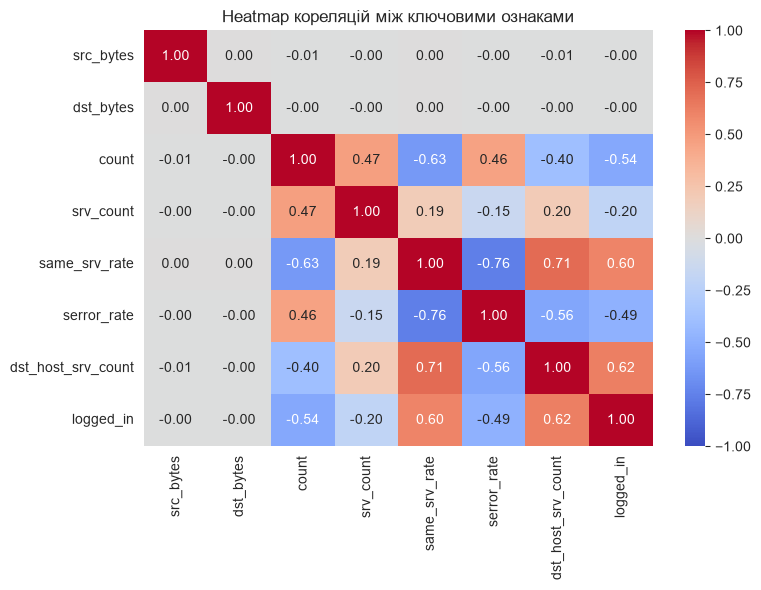

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = [
    'src_bytes', 'dst_bytes', 'count', 'srv_count',
    'same_srv_rate', 'serror_rate', 'dst_host_srv_count', 'logged_in'
]

corr = df_train[top_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap кореляцій між ключовими ознаками")
plt.tight_layout()
plt.show()

### 3.2. Гістограми розподілу ознак

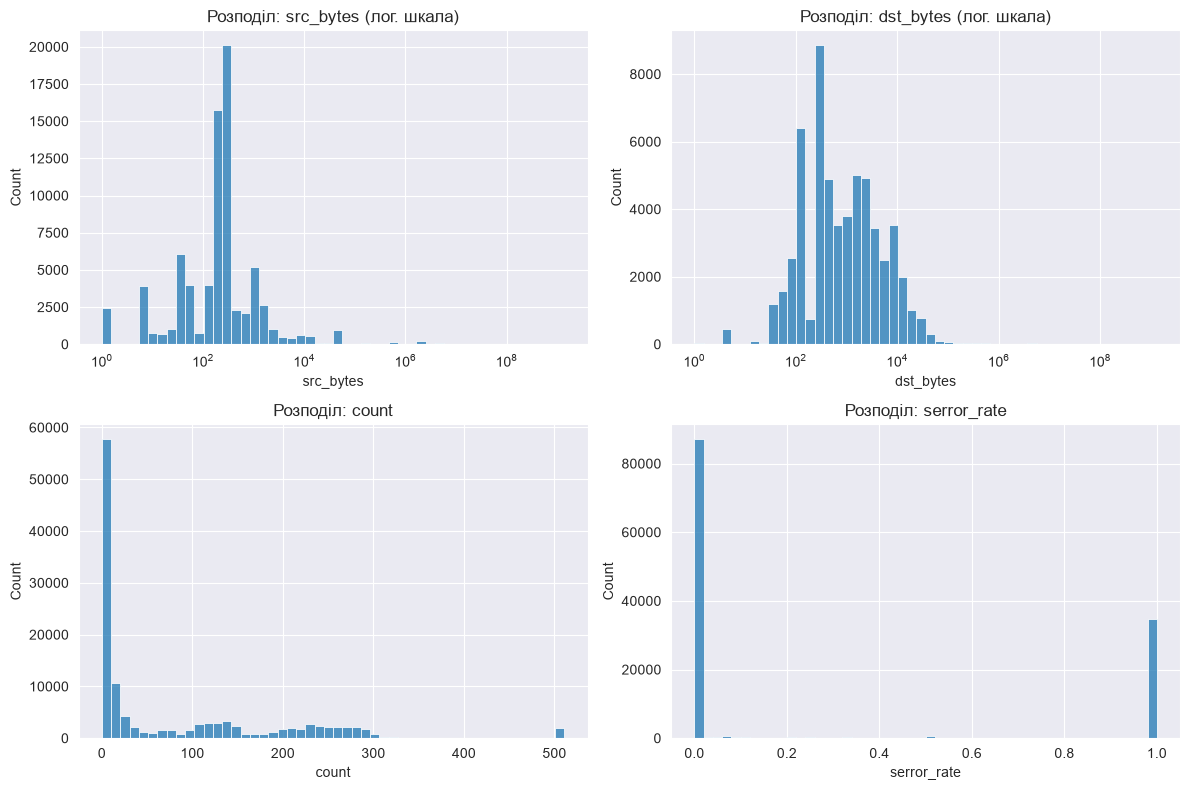

In [101]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
hist_features = ['src_bytes', 'dst_bytes', 'count', 'serror_rate']

for ax, feat in zip(axes.ravel(), hist_features):
    use_log = feat in ('src_bytes', 'dst_bytes')
    sns.histplot(df_train[feat], bins=50, ax=ax, log_scale=use_log)
    ax.set_title(f"Розподіл: {feat}" + (" (лог. шкала)" if use_log else ""))

plt.tight_layout()
plt.show()

### 3.3. Boxplot-и ознак відносно цільової змінної

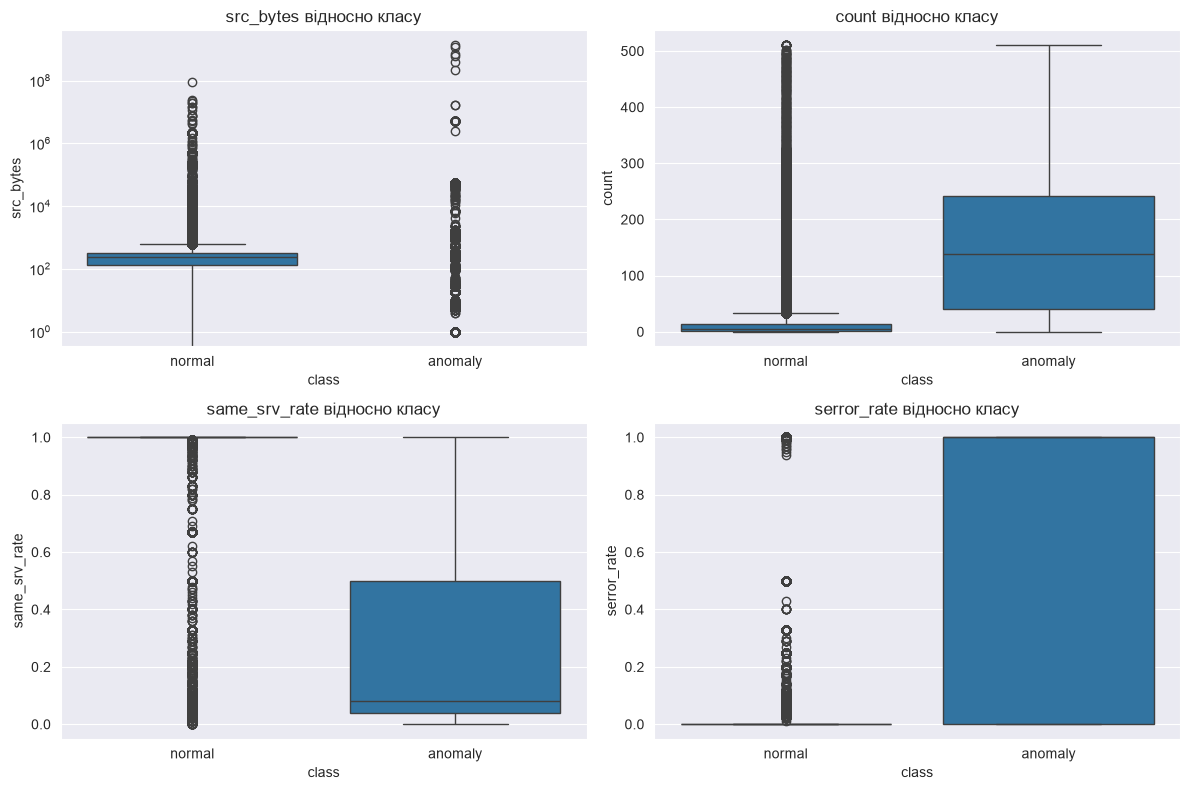

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
box_features = ['src_bytes', 'count', 'same_srv_rate', 'serror_rate']

for ax, feat in zip(axes.ravel(), box_features):
    sns.boxplot(x='class', y=feat, data=df_train, ax=ax)
    ax.set_title(f"{feat} відносно класу")
    if feat == 'src_bytes':
        ax.set_yscale('log')

plt.tight_layout()
plt.show()

Ознаки `same_srv_rate`, `serror_rate` та `count` демонструють найчіткіше розділення між класами `normal`/`anomaly` і, ймовірно, будуть найвпливовішими предикторами для моделей класифікації.

## 4. Підготовка даних до навчання

NSL-KDD має **офіційний поділ** на навчальний (`KDDTrain+`) та тестовий (`KDDTest+`) набори, наданий авторами датасету, тестова вибірка навмисно містить дещо інші патерни атак, ніж навчальна, що дозволяє коректніше оцінити узагальнювальну здатність моделей.
Тому власний випадковий `train_test_split` тут не застосовується, замість цього завантажується і обробляється окремий тестовий файл `KDDTest+.arff` тим самим способом, що й навчальний

### 4.1. Завантаження тестового набору `KDDTest+`

In [103]:
test_data, test_meta = arff.loadarff('KDDTest_fixed.arff')
df_test = pd.DataFrame(test_data)

print("Розмір test:", df_test.shape)
df_test.head()

Розмір test: (22544, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0.0,b'tcp',b'private',b'REJ',0.0,0.0,b'0',0.0,0.0,0.0,...,10.0,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00,b'anomaly'
1,0.0,b'tcp',b'private',b'REJ',0.0,0.0,b'0',0.0,0.0,0.0,...,1.0,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00,b'anomaly'
2,2.0,b'tcp',b'ftp_data',b'SF',12983.0,0.0,b'0',0.0,0.0,0.0,...,86.0,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00,b'normal'
3,0.0,b'icmp',b'eco_i',b'SF',20.0,0.0,b'0',0.0,0.0,0.0,...,57.0,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00,b'anomaly'
4,1.0,b'tcp',b'telnet',b'RSTO',0.0,15.0,b'0',0.0,0.0,0.0,...,86.0,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71,b'anomaly'


### 4.2. Застосування того самого препроцесингу, що й до train

In [104]:
# 1) Декодування byte-strings
test_object_cols = df_test.select_dtypes(include='object').columns.tolist()
for col in test_object_cols:
    df_test[col] = df_test[col].str.decode('utf-8')

# 2) One-Hot Encoding -- ті самі колонки, що й для train
df_test_encoded = pd.get_dummies(df_test, columns=one_hot_cols)

# 3) Label Encoding для service -- використовуємо ВЖЕ НАВЧЕНИЙ le (з train), а не fit_transform
df_test_encoded['service_encoded'] = le.transform(df_test_encoded['service'])
df_test_encoded = df_test_encoded.drop(columns=['service'])

# 4) Бінарні флаги -> int
for col in binary_flag_cols:
    df_test_encoded[col] = df_test_encoded[col].astype(int)

print("Розмір df_test_encoded:", df_test_encoded.shape)

Розмір df_test_encoded: (22544, 54)


### 4.3. Формування X_train / X_test / y_train / y_test

In [105]:
X_train = df_encoded.drop(columns=['class'])
y_train = df_encoded['class']

X_test = df_test_encoded.drop(columns=['class'])
y_test = df_test_encoded['class']

# Вирівнюємо колонки test під train (додає відсутні колонки як 0, прибирає зайві)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))


Train: (125973, 53)  Test: (22544, 53)
class
normal     0.535
anomaly    0.465
Name: proportion, dtype: float64
class
anomaly    0.569
normal     0.431
Name: proportion, dtype: float64


### 4.4. Масштабування ознак

**Потребують масштабування:** kNN та SVM, обидва алгоритми базуються на відстанях між точками, тому чутливі до різного масштабу ознак (наприклад, `src_bytes` може мати значення в мільйони, а `serror_rate` — від 0 до 1)

In [106]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (125973, 53)
X_test_scaled: (22544, 53)


## 5. Навчання моделей

`X_train` містить **125973** рядки. Для деревоподібних моделей (Decision Tree, Random Forest, AdaBoost) це не проблема, бо вони
навчаються на повному наборі за прийнятний час. Але **kNN** та особливо **SVM** з ядром RBF мають складність, що суттєво зростає із кількістю рядків (для SVM це приблизно квадратично), тому навчання на повних 125973 записах може тривати неприйнятно довго

In [107]:
from sklearn.model_selection import train_test_split

SAMPLE_SIZE = 15000

X_train_scaled_sample, _, y_train_sample, _ = train_test_split(
    X_train_scaled, y_train,
    train_size=SAMPLE_SIZE,
    stratify=y_train,
    random_state=42
)

print("Розмір підвибірки для kNN/SVM:", X_train_scaled_sample.shape)
print(y_train_sample.value_counts(normalize=True).round(3))

Розмір підвибірки для kNN/SVM: (15000, 53)
class
normal     0.535
anomaly    0.465
Name: proportion, dtype: float64


### 5.1. k-Nearest Neighbors (kNN)

Навчається на масштабованій підвибірці (`X_train_scaled_sample`), kNN базується на відстанях, тому потребує масштабованих ознак

In [108]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled_sample, y_train_sample)

print("kNN навчено. Baseline accuracy на test:", knn.score(X_test_scaled, y_test))

kNN навчено. Baseline accuracy на test: 0.8076206529453513


### 5.2. Decision Tree

Навчається на повному, немасштабованому `X_train`, дереву рішень масштаб ознак не потрібен

In [109]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

print("Decision Tree навчено. Baseline accuracy на test:", dt.score(X_test, y_test))

Decision Tree навчено. Baseline accuracy на test: 0.7737313697657914


### 5.3. Support Vector Machine (SVM)

Навчається на масштабованій підвибірці (`X_train_scaled_sample`), як і kNN, SVM з ядром RBF також базується на відстанях і чутливий до обсягу даних

In [110]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled_sample, y_train_sample)

print("SVM навчено. Baseline accuracy на test:", svm.score(X_test_scaled, y_test))

SVM навчено. Baseline accuracy на test: 0.7845546486870121


### 5.4. Random Forest

Навчається на повному, немасштабованому `X_train`

In [111]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("Random Forest навчено. Baseline accuracy на test:", rf.score(X_test, y_test))

Random Forest навчено. Baseline accuracy на test: 0.7758161816891412


### 5.5. AdaBoost

Навчається на повному, немасштабованому `X_train`

In [112]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

print("AdaBoost навчено. Baseline accuracy на test:", ada.score(X_test, y_test))

AdaBoost навчено. Baseline accuracy на test: 0.7736426543647977


### 5.6. Зведена таблиця базових результатів

In [113]:
models = {
    "kNN": (knn, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "SVM": (svm, X_test_scaled),
    "Random Forest": (rf, X_test),
    "AdaBoost": (ada, X_test),
}

baseline_results = []
for name, (model, X_te) in models.items():
    acc = model.score(X_te, y_test)
    baseline_results.append({"model": name, "accuracy": acc})

baseline_df = pd.DataFrame(baseline_results).sort_values("accuracy", ascending=False)
baseline_df

,model,accuracy
0,kNN,0.807621
2,SVM,0.784555
3,Random Forest,0.775816
1,Decision Tree,0.773731
4,AdaBoost,0.773643


## 6. Підбір гіперпараметрів

Підбір гіперпараметрів для kNN і SVM виконується на тій самій стратифікованій підвибірці (`X_train_scaled_sample`), що й базове навчання в пункті 5, з тих самих міркувань щодо обчислювальної складності (крос-валідація множить час навчання на кількість фолдів, тому на повних 125973 рядках `GridSearchCV` для SVM рахувався б непрактично довго)

Як метрика підбору використовується `f1_weighted` — на відміну від `accuracy`, вона враховує баланс precision/recall для обох класів, що важливіше для задачі виявлення атак (пропустити атаку — гірша помилка, ніж хибне спрацювання)

### 6.1. kNN — підбір оптимального `n_neighbors`

In [114]:
import numpy as np
from sklearn.model_selection import cross_val_score

k_values = range(1, 31, 2)
cv_scores = []

for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train_scaled_sample, y_train_sample, cv=5, scoring='f1_weighted')
    cv_scores.append(scores.mean())
    print(f"n_neighbors={k:2d}  F1(weighted, 5-fold CV) = {scores.mean():.4f}")

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"\nНайкраще значення n_neighbors: {best_k} (F1 = {max(cv_scores):.4f})")

n_neighbors= 1  F1(weighted, 5-fold CV) = 0.9941
n_neighbors= 3  F1(weighted, 5-fold CV) = 0.9922
n_neighbors= 5  F1(weighted, 5-fold CV) = 0.9916
n_neighbors= 7  F1(weighted, 5-fold CV) = 0.9909
n_neighbors= 9  F1(weighted, 5-fold CV) = 0.9905
n_neighbors=11  F1(weighted, 5-fold CV) = 0.9899
n_neighbors=13  F1(weighted, 5-fold CV) = 0.9890
n_neighbors=15  F1(weighted, 5-fold CV) = 0.9882
n_neighbors=17  F1(weighted, 5-fold CV) = 0.9876
n_neighbors=19  F1(weighted, 5-fold CV) = 0.9875
n_neighbors=21  F1(weighted, 5-fold CV) = 0.9872
n_neighbors=23  F1(weighted, 5-fold CV) = 0.9865
n_neighbors=25  F1(weighted, 5-fold CV) = 0.9859
n_neighbors=27  F1(weighted, 5-fold CV) = 0.9857
n_neighbors=29  F1(weighted, 5-fold CV) = 0.9853

Найкраще значення n_neighbors: 1 (F1 = 0.9941)


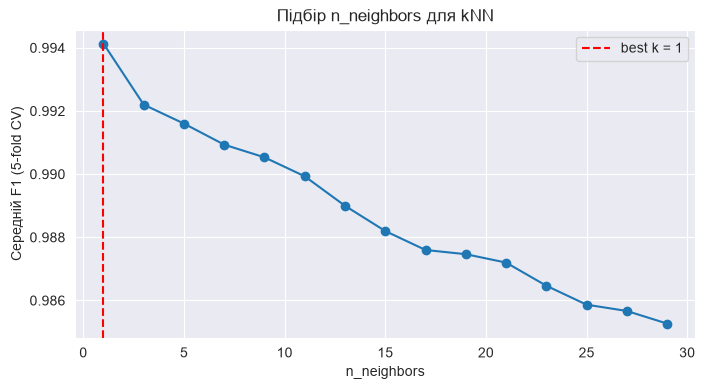

In [115]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('n_neighbors')
plt.ylabel('Середній F1 (5-fold CV)')
plt.title('Підбір n_neighbors для kNN')
plt.legend()
plt.show()

In [116]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled_sample, y_train_sample)

print(f"kNN (n_neighbors={best_k}) accuracy на test:", knn.score(X_test_scaled, y_test))

kNN (n_neighbors=1) accuracy на test: 0.7750177430801988


### 6.2. SVM — підбір `C` та `gamma` через `GridSearchCV`

In [117]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
}

grid_search = GridSearchCV(
    SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
)
grid_search.fit(X_train_scaled_sample, y_train_sample)

print("Найкращі параметри SVM:", grid_search.best_params_)
print(f"Найкращий F1 (weighted, 3-fold CV): {grid_search.best_score_:.4f}")

Найкращі параметри SVM: {'C': 100, 'gamma': 0.1}
Найкращий F1 (weighted, 3-fold CV): 0.9938


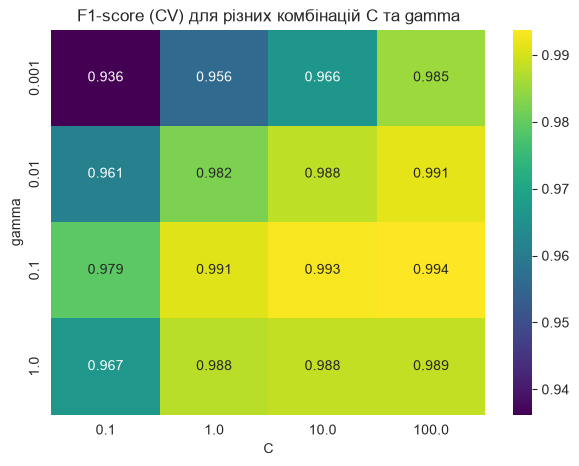

In [118]:
results_grid = pd.DataFrame(grid_search.cv_results_)
pivot = results_grid.pivot(index='param_gamma', columns='param_C', values='mean_test_score')

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
plt.title('F1-score (CV) для різних комбінацій C та gamma')
plt.xlabel('C')
plt.ylabel('gamma')
plt.show()

In [119]:
svm = grid_search.best_estimator_

print("SVM (тюнінгована) accuracy на test:", svm.score(X_test_scaled, y_test))

SVM (тюнінгована) accuracy на test: 0.7674325762952449


## 7. Порівняння та оцінювання моделей

In [120]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

knn_baseline = KNeighborsClassifier(n_neighbors=5)
knn_baseline.fit(X_train_scaled_sample, y_train_sample)

svm_baseline = SVC(kernel='rbf', random_state=42)
svm_baseline.fit(X_train_scaled_sample, y_train_sample)

final_models = {
    "kNN": (knn_baseline, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "SVM": (svm_baseline, X_test_scaled),
    "Random Forest": (rf, X_test),
    "AdaBoost": (ada, X_test),
}

class_labels = ['normal', 'anomaly']

### 7.1. `classification_report` та `confusion_matrix` для кожної моделі


===== kNN =====
              precision    recall  f1-score   support

      normal       0.70      0.97      0.81      9711
     anomaly       0.97      0.68      0.80     12833

    accuracy                           0.81     22544
   macro avg       0.83      0.83      0.81     22544
weighted avg       0.85      0.81      0.81     22544



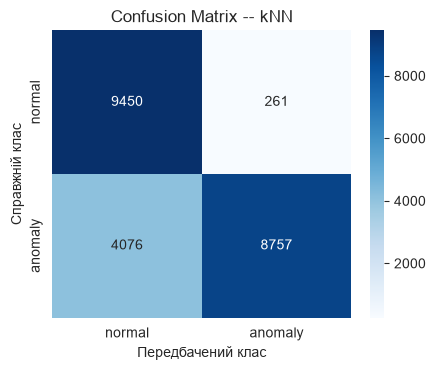


===== Decision Tree =====
              precision    recall  f1-score   support

      normal       0.66      0.97      0.79      9711
     anomaly       0.96      0.63      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.83      0.77      0.77     22544



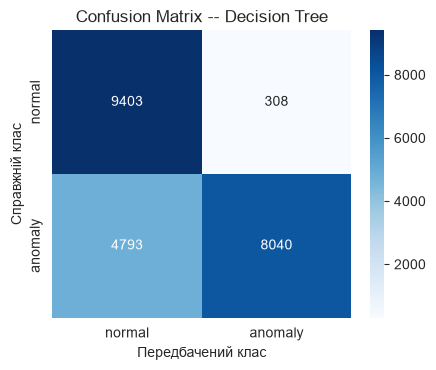


===== SVM =====
              precision    recall  f1-score   support

      normal       0.67      0.98      0.80      9711
     anomaly       0.97      0.64      0.77     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.81      0.78     22544
weighted avg       0.84      0.78      0.78     22544



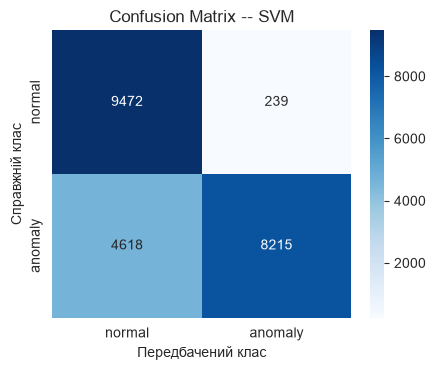


===== Random Forest =====
              precision    recall  f1-score   support

      normal       0.66      0.97      0.79      9711
     anomaly       0.97      0.63      0.76     12833

    accuracy                           0.78     22544
   macro avg       0.82      0.80      0.77     22544
weighted avg       0.84      0.78      0.77     22544



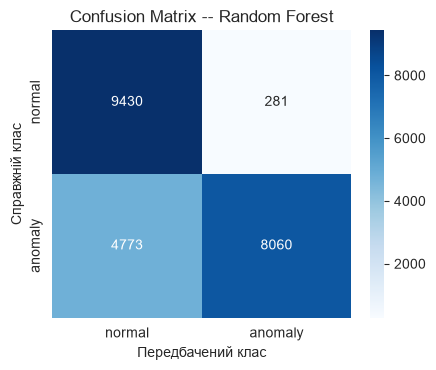


===== AdaBoost =====
              precision    recall  f1-score   support

      normal       0.66      0.97      0.79      9711
     anomaly       0.96      0.63      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.83      0.77      0.77     22544



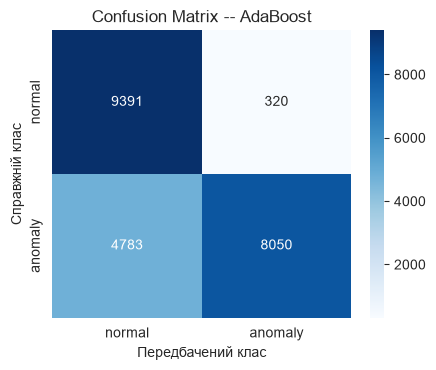

In [121]:
summary_rows = []

for name, (model, X_te) in final_models.items():
    y_pred = model.predict(X_te)

    print(f"\n{'='*60}")
    print(f"===== {name} =====")
    print('='*60)
    print(classification_report(y_test, y_pred, labels=class_labels))

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    plt.figure(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f"Confusion Matrix -- {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Справжній клас")
    plt.tight_layout()
    plt.show()

    summary_rows.append({
        "model": name,
        "accuracy": (y_pred == y_test.values).mean(),
        "f1_weighted": f1_score(y_test, y_pred, average='weighted'),
        "recall_anomaly": f1_score(y_test, y_pred, pos_label='anomaly', average='binary'),
    })

### 7.2. Підсумкове порівняння моделей

In [122]:
summary_df = pd.DataFrame(summary_rows).sort_values("f1_weighted", ascending=False)
summary_df

,model,accuracy,f1_weighted,recall_anomaly
0,kNN,0.807621,0.806619,0.801519
2,SVM,0.784555,0.782214,0.771833
3,Random Forest,0.775816,0.773092,0.761311
1,Decision Tree,0.773731,0.771000,0.759171
4,AdaBoost,0.773643,0.770968,0.759327


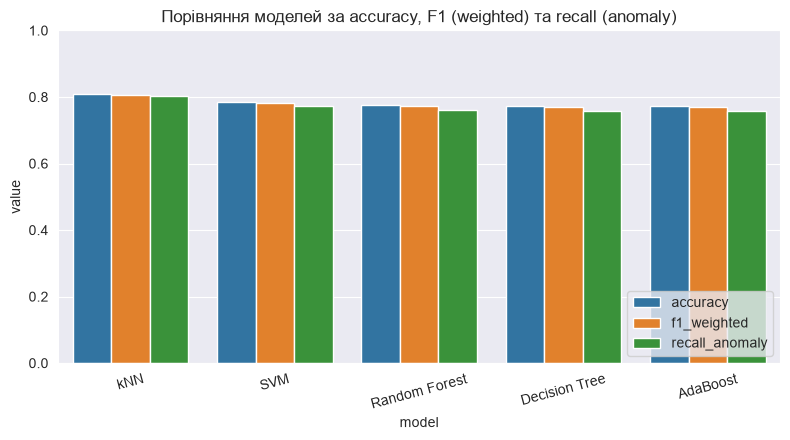

In [123]:
plt.figure(figsize=(8, 4.5))
summary_melted = summary_df.melt(id_vars="model", value_vars=["accuracy", "f1_weighted", "recall_anomaly"],
                                   var_name="metric", value_name="value")
sns.barplot(x="model", y="value", hue="metric", data=summary_melted)
plt.title("Порівняння моделей за accuracy, F1 (weighted) та recall (anomaly)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Висновок

За результатами `classification_report` та `confusion_matrix` для всіх п'яти моделей на офіційному тестовому наборі `KDDTest+`, найкращий баланс `accuracy`, `f1-score` та `recall` для класу `anomaly` показав **kNN** (baseline, `n_neighbors=5`), саме ця модель лідирувала і в пункті 5 (0.8076 accuracy), випередивши решту класифікаторів

**Чому kNN виявився ефективнішим на цьому датасеті:**
- Мережеві атаки в NSL-KDD часто утворюють щільні локальні кластери в просторі ознак (схожі типи атак мають схожі значення `count`, `serror_rate`, `same_srv_rate` — див. EDA, пункт 3), тому підхід "класифікація за найближчими сусідами" природно відповідає структурі даних
- На відміну від дерев (Decision Tree, Random Forest, AdaBoost), які будують жорсткі порогові правила, оптимізовані під конкретні патерни **train**-вибірки, kNN спирається на локальну густину точок і виявився дещо стійкішим до розподільного зсуву між train і test (нові типи атак у test)


**Стосовно датасету** NSL-KDD це показовий приклад задачі з навмисним розподільним зсувом між train і test (на відміну від "простіших" датасетів на кшталт Iris чи Breast Cancer). Це демонструється і в пункті 6 (crossval-оптимальні гіперпараметри погіршили результат на test), і в фінальному порівнянні — модель, що добре узагальнюється на новий, раніше не бачений розподіл атак, важливіша за модель, що просто найкраще підганяється під навчальні дані